# Woche 7: Data Cleaning - Übung am eigenen Projekt

**Ziel dieser Übung:** Nachdem Du die wichtigsten Aspekte des Data Cleanings am Airbnb-Beispiel kennengelernt hast, wendest Du nun dieses Wissen Schritt für Schritt auf Deinen eigenen Datensatz an.

**Arbeitsweise:**
- Arbeite die Aufgaben nacheinander durch
- Nutze die Code-Zellen für Deine Implementierung
- Orientiere Dich an den Beispielen aus dem Airbnb-Notebook
- Das bereinigte Dataset speicherst Du am Ende ab

---
## 1. Daten einlesen und Bibliotheken importieren

**Aufgabe:** Importiere die notwendigen Bibliotheken und lade Ihren Datensatz.

**Hinweise:**
- Importiere: `pandas`, `numpy`, `matplotlib.pyplot`, `seaborn`
- Setze einen Zufallsseed für Reproduzierbarkeit
- Lade Deinen CSV-Datensatz mit `pd.read_csv()`

In [10]:
pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\zhent\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [58]:
# Bibliotheken importieren
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

# Zufallsseed setzen


# Datensatz einlesen
# df = pd.read_csv('dein_datensatz.csv')
df = pd.read_csv('giessdenkiez.csv', sep=";")
df_clean = df.copy()

---
## 2. Ersten Überblick verschaffen

**Aufgabe:** Verschaffe Dir einen ersten Überblick über Deine Datensatz.

**Was Du prüfen solltest:**
- Wie viele Zeilen und Spalten hat der Datensatz?
- Welche Spalten gibt es und welche Datentypen haben sie?
- Wie sehen die ersten Zeilen aus?

In [59]:
# Dimensionen des Datensatzes
print("Shape:", df_clean.shape)

# Erste Zeilen anzeigen
display(df.head())

# Informationen zu Spalten und Datentypen
df.info()

Shape: (61563, 10)


,id,lng,lat,bezirk,art_dtsch,gattung_deutsch,strname,pflanzjahr,timestamp,bewaesserungsmenge_in_liter
0,00008100:002cba28,1.339.275,5.250.416,Friedrichshain-Kreuzberg,Japanischer Schnurbaum,Schnurbaum,NaN,2020.0,2026-10-01 00:00:00+00:00,200.0
1,00008100:002a3e71,1.332.611,5.247.638,Tempelhof-Schöneberg,Thüringische Säulen-Eberesche,Mehlbeere,Südwestkorso,2020.0,2026-10-07 00:00:00+00:00,10.0
2,00008100:0016c351,1.325.881,5.244.773,Steglitz-Zehlendorf,Echte Mehlbeere,Mehlbeere,Eisvogelweg,2017.0,2026-10-07 00:00:00+00:00,40.0
3,00008100:0022f2c4,132.586,5.244.785,Steglitz-Zehlendorf,Echte Mehlbeere,Mehlbeere,Eisvogelweg,2017.0,2026-10-07 00:00:00+00:00,40.0
4,00008100:00159eb1,1.339.817,5.254.639,Mitte,Gewöhnliche Hopfenbuche,Hopfenbuche,Gleimstraße,2011.0,2026-10-10 00:00:00+00:00,10.0


<class 'pandas.DataFrame'>
RangeIndex: 61563 entries, 0 to 61562
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           61563 non-null  str    
 1   lng                          61366 non-null  str    
 2   lat                          61366 non-null  str    
 3   bezirk                       61563 non-null  str    
 4   art_dtsch                    61563 non-null  str    
 5   gattung_deutsch              59995 non-null  str    
 6   strname                      57834 non-null  str    
 7   pflanzjahr                   61358 non-null  float64
 8   timestamp                    61563 non-null  str    
 9   bewaesserungsmenge_in_liter  61563 non-null  float64
dtypes: float64(2), str(8)
memory usage: 4.7 MB


---
## 3. Fehlende Werte identifizieren

**Aufgabe:** Untersuche Deine Datensatz auf fehlende Werte.

**Was Du tun solltest:**
- Zähle fehlende Werte pro Spalte
- Berechne den Prozentsatz fehlender Werte
- Visualisiere fehlende Werte (optional: Heatmap)

In [60]:
# Fehlende Werte zählen
missing = df_clean.isnull().sum()

# Prozentsatz fehlender Werte berechnen
missing_pct = (missing/len(df_clean))*100
missing_df=pd.DataFrame({
    'Spalte': missing.index,
    'Fehlend': missing.values,
    'Prozent':missing_pct.values})
missing_df = missing_df[missing_df['Fehlend'] > 0]
display(missing_df)

,Spalte,Fehlend,Prozent
1,lng,197,0.319997
2,lat,197,0.319997
5,gattung_deutsch,1568,2.546984
6,strname,3729,6.057210
7,pflanzjahr,205,0.332992


---
## 4. Fehlende Werte behandeln

**Aufgabe:** Entscheide für jede Spalte mit fehlenden Werten, wie Du damit umgehst.

**Mögliche Strategien:**
- Zeilen löschen (bei wenigen fehlenden Werten)
- Spalten löschen (bei sehr vielen fehlenden Werten)
- Fehlende Werte imputieren:
  - Numerische Spalten: Median oder Mittelwert
  - Kategoriale Spalten: Modus oder neue Kategorie

**Dokumentiere Deine Entscheidungen!**

In [61]:
vorher = len(df_clean)

In [62]:
# --- Umgang mit fehlenden Werten ---

# lng, lat: Ohne Koordinaten kann ein Baum nicht genau verortet werden.
# pflanzjahr: Das Pflanzjahr bestimmt das Baumalter, das Wachstum und Gießverhalten beeinflusst.
# gattung_deutsch: die Gattung is auch ein wichtig Variable in Bezug auf wie viel Wasser ein bestimmt art Baum braucht
# Entscheidung: Zeilen mit fehlenden Werten in den Spalten "lng, lat, pflanzjahr, gattung_deutsch" werden entfernt.
df_clean = df_clean.dropna(subset=['lng', 'lat', 'pflanzjahr','gattung_deutsch'])

# strname: der Standort ist bereits über die Koordinaten bestimmt.
# Entscheidung: Fehlende Werte werden mit "Unbekannt" aufgefüllt, die Zeilen bleiben erhalten.
df_clean['strname'] = df_clean['strname'].fillna('Unbekannt')

In [63]:
# Überprüfung: Sind alle fehlenden Werte behandelt?
print(df_clean.isnull().sum())

id                             0
lng                            0
lat                            0
bezirk                         0
art_dtsch                      0
gattung_deutsch                0
strname                        0
pflanzjahr                     0
timestamp                      0
bewaesserungsmenge_in_liter    0
dtype: int64


In [64]:
nachher = len(df_clean)

print("Zeilen vorher:", vorher)
print("Zeilen nachher:", nachher)
print(f"Percentage entfernten Zeilen: {round((vorher-nachher)/vorher*100,1)}%")

Zeilen vorher: 61563
Zeilen nachher: 59602
Percentage entfernten Zeilen: 3.2%


In [65]:
# nach die Behandlung von fehlende Daten sind nur 0.7% der original Datenset entfert, die meisten sind geblieben. Das is kein Stürung für die ganze Forschung

---
## 5. Duplikate identifizieren und entfernen

**Aufgabe:** Prüfe, ob Dein Datensatz doppelte Zeilen enthält.

**Was Du tun solltest:**
- Zähle die Anzahl doppelter Zeilen
- Entferne Duplikate (falls vorhanden)
- Überprüfe die neue Anzahl der Zeilen

In [66]:
# Als Duplikat gilt eine Zeile, die in allen Spalten identisch ist:
# gleicher Baum (id), gleicher Local, gleicher Namen, gleicher Zeitpunkt und gleiche Gießmenge.
# Dass derselbe Baum zum selben Zeitpunkt zweimal mit exakt derselben Menge gegossen wird, ist praktisch ausgeschlossen. Solche Zeilen sind daher doppelt importierte Einträge
# Entscheidung: die doppelte Zeilen werden entfert
# Anzahl doppelter Zeilen

duplikate = df_clean[df_clean.duplicated(keep=False)].sort_values(['timestamp', 'id'])
print("Anzahl Duplikate:", df_clean.duplicated().sum())
display(duplikate.head(10))

Anzahl Duplikate: 192


,id,lng,lat,bezirk,art_dtsch,gattung_deutsch,strname,pflanzjahr,timestamp,bewaesserungsmenge_in_liter
835,00008100:00163c6c,1.340.772,524.916,Friedrichshain-Kreuzberg,Schwarz-Ahorn 'Faassen's Black',Ahorn,Fontanepromenade,1978.0,2022-05-10 13:00:00+00:00,5.0
47946,00008100:00163c6c,1.340.772,524.916,Friedrichshain-Kreuzberg,Schwarz-Ahorn 'Faassen's Black',Ahorn,Fontanepromenade,1978.0,2022-05-10 13:00:00+00:00,5.0
46023,00008100:000c09e9,1.329.324,5.250.396,Charlottenburg-Wilmersdorf,Echter Rotdorn,Weißdorn,Friedbergstraße,2001.0,2022-06-01 13:00:00+00:00,30.0
60038,00008100:000c09e9,1.329.324,5.250.396,Charlottenburg-Wilmersdorf,Echter Rotdorn,Weißdorn,Friedbergstraße,2001.0,2022-06-01 13:00:00+00:00,30.0
50584,00008100:000c09ea,1.329.334,5.250.397,Charlottenburg-Wilmersdorf,Echter Rotdorn,Weißdorn,Friedbergstraße,1991.0,2022-06-01 13:00:00+00:00,30.0
50612,00008100:000c09ea,1.329.334,5.250.397,Charlottenburg-Wilmersdorf,Echter Rotdorn,Weißdorn,Friedbergstraße,1991.0,2022-06-01 13:00:00+00:00,30.0
39078,00008100:000c09e9,1.329.324,5.250.396,Charlottenburg-Wilmersdorf,Echter Rotdorn,Weißdorn,Friedbergstraße,2001.0,2022-06-09 13:00:00+00:00,30.0
41800,00008100:000c09e9,1.329.324,5.250.396,Charlottenburg-Wilmersdorf,Echter Rotdorn,Weißdorn,Friedbergstraße,2001.0,2022-06-09 13:00:00+00:00,30.0
8287,00008100:000cede7,1.329.315,5.250.394,Charlottenburg-Wilmersdorf,Echter Rotdorn,Weißdorn,Friedbergstraße,2000.0,2022-06-09 13:00:00+00:00,30.0
17366,00008100:000cede7,1.329.315,5.250.394,Charlottenburg-Wilmersdorf,Echter Rotdorn,Weißdorn,Friedbergstraße,2000.0,2022-06-09 13:00:00+00:00,30.0


In [67]:
# Duplikate entfernen
df_clean = df_clean.drop_duplicates()

# Neue Dimensionen prüfen
print(f'Nach Entfernung {df_clean.shape[0]} Zeilen')

Nach Entfernung 59410 Zeilen


---
## 6. Datentypen überprüfen und anpassen

**Aufgabe:** Stelle sicher, dass alle Spalten die richtigen Datentypen haben.

**Was Du prüfen solltest:**
- Sind numerische Spalten als `int` oder `float` kodiert?
- Sind kategoriale Spalten als `object` oder `category` kodiert?
- Müssen Datentypen konvertiert werden?

In [68]:
# Datentypen anzeigen
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 61563 entries, 0 to 61562
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           61563 non-null  str    
 1   lng                          61366 non-null  str    
 2   lat                          61366 non-null  str    
 3   bezirk                       61563 non-null  str    
 4   art_dtsch                    61563 non-null  str    
 5   gattung_deutsch              59995 non-null  str    
 6   strname                      57834 non-null  str    
 7   pflanzjahr                   61358 non-null  float64
 8   timestamp                    61563 non-null  str    
 9   bewaesserungsmenge_in_liter  61563 non-null  float64
dtypes: float64(2), str(8)
memory usage: 4.7 MB


In [69]:
print(df_clean.isna().sum())
print(df_clean.shape)

id                             0
lng                            0
lat                            0
bezirk                         0
art_dtsch                      0
gattung_deutsch                0
strname                        0
pflanzjahr                     0
timestamp                      0
bewaesserungsmenge_in_liter    0
dtype: int64
(59410, 10)


In [70]:
# Datentypen konvertieren 
# Koordinaten: lng, lat soll the format 13.xxx und 52.xxx (Lager von Berlin) haben, in format float
for col in ['lng', 'lat']:
    ziffern = df_clean[col].astype(str).str.replace('.', '', regex=False)
    df_clean[col] = (ziffern.str[:2] + '.' + ziffern.str[2:]).astype(float)
    
# pflanzjahr von float64 zu int konvertieren
df_clean['pflanzjahr'] = df_clean['pflanzjahr'].astype(int)

# bewaesserungsmenge_in_liter von float64 zu int konvertieren
df_clean['bewaesserungsmenge_in_liter'] = df_clean['bewaesserungsmenge_in_liter'].astype(int)

# timestamp von str zu datetime konvertieren
df_clean['timestamp'] = pd.to_datetime(df_clean['timestamp'], format='ISO8601')

---
## 7. Ausreißer identifizieren

**Aufgabe:** Identifiziere Ausreißer in numerischen Spalten.

**Methoden:**
- Visualisierung mit Boxplots
- IQR-Methode (Interquartile Range)
- Statistische Analyse (describe)

**Wichtig:** Entscheide für jeden Ausreißer, ob er:
- Ein Fehler ist (→ entfernen oder korrigieren)
- Ein echter extremer Wert ist (→ behalten)

timestamp
2020    15834
2021     7804
2022    17573
2023     6878
2024     3508
2025     4347
2026     3466
Name: count, dtype: int64


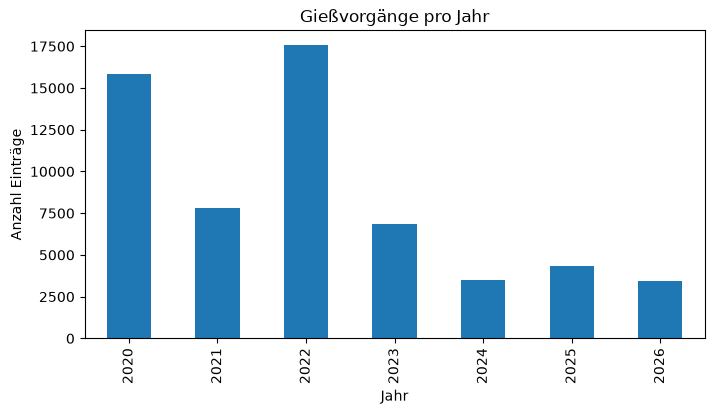

In [71]:
# Anzahl der Gießvorgänge pro Jahr
jahr = df_clean['timestamp'].dt.year
pro_jahr = jahr.value_counts().sort_index()
print(pro_jahr)

pro_jahr.plot(kind='bar', figsize=(8, 4), title='Gießvorgänge pro Jahr')
plt.xlabel('Jahr'); plt.ylabel('Anzahl Einträge')
plt.show()

bezirk
Charlottenburg-Wilmersdorf    8793
Pankow                        8440
Mitte                         7869
Tempelhof-Schöneberg          7549
Friedrichshain-Kreuzberg      7530
Steglitz-Zehlendorf           5157
Neukölln                      4016
Treptow-Köpenick              3325
Lichtenberg                   2908
Reinickendorf                 2574
Marzahn-Hellersdorf            767
Spandau                        482
Name: count, dtype: int64


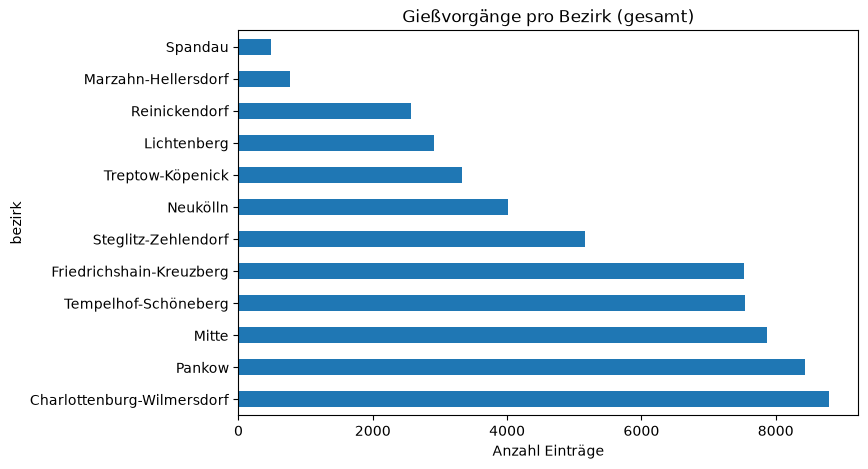

In [72]:
# Einträge pro Bezirk
pro_bezirk = df_clean['bezirk'].value_counts()
print(pro_bezirk)
pro_bezirk.plot(kind='barh', figsize=(8, 5), title='Gießvorgänge pro Bezirk (gesamt)')
plt.xlabel('Anzahl Einträge')
plt.show()

count    59410.000000
mean        39.031140
std         46.697154
min          1.000000
25%         10.000000
50%         30.000000
75%         50.000000
max       5040.000000
Name: bewaesserungsmenge_in_liter, dtype: float64


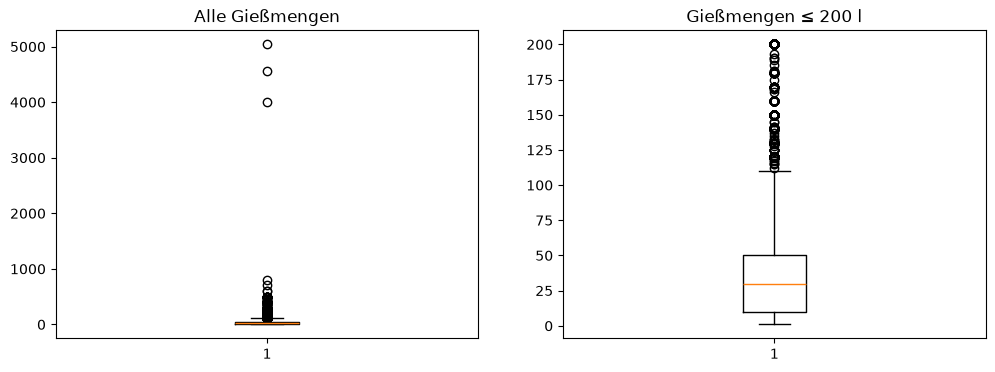

In [73]:
# Bewaesserungsmenge
menge = df_clean['bewaesserungsmenge_in_liter']
print(menge.describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4)) #fig - diagram, 1row 2col（2 sub diagrams）
axes[0].boxplot(menge) #箱线图 boxplot, inhalt: menge
axes[0].set_title('Alle Gießmengen') #title
axes[1].boxplot(menge[menge <= 200])
axes[1].set_title('Gießmengen ≤ 200 l')
plt.show()

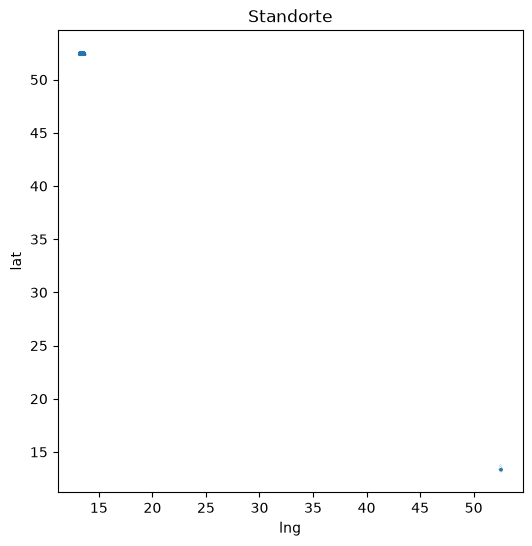

In [74]:
# lng, lat
plt.figure(figsize=(6, 6))
plt.scatter(df_clean['lng'], df_clean['lat'], s=0.001) #s: size of each dot
plt.xlabel('lng'); plt.ylabel('lat'); plt.title('Standorte')
plt.show()

---
## 8. Ausreißer behandeln

**Aufgabe:** Behandle die identifizierten Ausreißer entsprechend Deiner Analyse.

**Mögliche Strategien:**
- Ausreißer entfernen (wenn sie Fehler sind)
- Ausreißer behalten (wenn sie valide sind)
- Ausreißer begrenzen (Capping/Flooring)

**Dokumentiere Deine Entscheidungen!**

In [75]:
# Einträge pro Jahr:
# Die Anzahl der Einträge schwankt stark zwischen den Jahren (Höchstwerte 2020 und 2022, deutlicher Rückgang ab 2023). 
# Sie spiegelt vor allem die Nutzung der App wider und nicht den tatsächlichen Wasserbedarf der Bäume. 
# Das Jahr wird in der Analysesphase nicht als Variable verwendet, betrachtet werden saisonale Muster innerhalb eines Jahres (Monat, Tag).

In [76]:
# Einträge pro Bezirk:
# Da die Datensatz so groß ist (über 60000 Zeilen), konzentriert sich die Analyse auf den Bezirk mit den meisten Einträgen: Charlottenburg-Wilmersdorf.
# (So werden Unterschiede zwischen den Bezirken ausgeschlossen)
df_clean = df_clean[df_clean['bezirk'] == 'Charlottenburg-Wilmersdorf']
print(f"Shape nach Filterung auf Charlottenburg-Wilmersdorf: {df_clean.shape[0]} Zeilen")

Shape nach Filterung auf Charlottenburg-Wilmersdorf: 8793 Zeilen


In [77]:
# Bewaesserungsmenge:
# Die einzelne extrem hohe Werte (über 5.000 l pro Eintrag) ist nicht realistisch und wird entfernt
# Um die Grenze von Bewaesserungsmenge zu festlegen, gibt es bei den GitHub Quellcode ein Paar Hinweise:
# GitHub: github.com/technologiestiftung/giessdenkiez-de
# Datei: src/components/tree-detail/hooks/use-tree-water-needs-data.tsx
# Gemaß Quellcode sind die vorgeschlagene Menge die auf der App zeigt werden wie folgendes:
# pro 30 Tage: Jungbäume (BABY) 100 l, JUNIOR 200 l, SENIOR 300 l, unbekannt 200 l
# Ein Gießhinweis wird nur für JUNIOR- und unbekannte Bäume angezeigt (max. 200 l in 30 Tagen).
# -> Das bedeutet: Ein einzelner Eintrag über 200 l übersteigt den von der Plattform empfohlenen Bedarf eines ganzen Monats
# -> Daher kann man die Grenze als 200l setzen
menge = df_clean['bewaesserungsmenge_in_liter']
print("Einträge über 200 l:", (menge > 200).sum())

df_clean = df_clean[df_clean['bewaesserungsmenge_in_liter'] <= 200]
print(f"Shape nach Entfernen unplausibler Gießmengen: {df_clean.shape[0]} Zeilen")

Einträge über 200 l: 20
Shape nach Entfernen unplausibler Gießmengen: 8773 Zeilen


In [78]:
# Koordinaten: lng, lat
# Berlin liegt bei lng ≈ 13.x und lat ≈ 52.x. 
# Das Diagram zeigt dass bei einige Einträgen Längen- und Breitengrad vertauscht sind.
# Da der Fehler eindeutig ist, werden die Werte zurückgetauscht statt die Zeilen zu entfernen.

vertauscht = df_clean['lng'] > df_clean['lat']
print("Vertauschte Koordinaten:", vertauscht.sum())
df_clean.loc[vertauscht, ['lng', 'lat']] = df_clean.loc[vertauscht, ['lat', 'lng']].values

Vertauschte Koordinaten: 12


---
## Zusatz: Datenquellen prüfen

**Aufgaben:**
- Es wird geprüft, ob alle Bäume im Gieß-Datensatz im offiziellen Baumkataster enthalten sind.
- Quellen Baumkataster: https://daten.berlin.de/datensaetze/baumbestand-berlin-wfs-48ad3a23
  
(Es wird jetzt die Datenquellen gefrüft weil nach Filterung von Bezirk is die Datenmenge deutlich kleiner geworden und daher die Arbeitsaufwand auch kleiner)

In [79]:
# Daten aus jeweils Strassenbäum- und Anlagenbäum-Tabellen lesen
strasse = pd.read_csv('baumbestand_strassenbaeume.csv', usecols=['pitid'], dtype=str)  
anlage = pd.read_csv('baumbestand_anlagenbaeume.csv', usecols=['pitid'], dtype=str)

# Berechnen wie viel Baum-IDs aus df_clean wirklich in die zwei Baumkataster Tabellen
ids = pd.Series(df_clean['id'].unique())
in_strasse = ids.isin(strasse['pitid'])
in_anlage = ids.isin(anlage['pitid'])

# Prüfen ob die Zahl stimmt
print("Bäume im Gieß-Datensatz:", len(ids))
print("davon Straßenbäume:     ", (in_strasse & ~in_anlage).sum())
print("davon Anlagenbäume:     ", (in_anlage & ~in_strasse).sum())
print("in beiden Tabellen:     ", (in_strasse & in_anlage).sum())
print("nicht gefunden:         ", (~in_strasse & ~in_anlage).sum())
richtig = ((in_strasse & ~in_anlage).sum() + (in_anlage & ~in_strasse).sum() == len(ids)
            and (in_strasse & in_anlage).sum()==0 and (~in_strasse & ~in_anlage).sum()==0)
print("Sind alle Bäume eindeutig im Baumkataster zugeordnet?", richtig)

Bäume im Gieß-Datensatz: 1452
davon Straßenbäume:      1420
davon Anlagenbäume:      32
in beiden Tabellen:      0
nicht gefunden:          0
Sind alle Bäume eindeutig im Baumkataster zugeordnet? True


---
## Zusatz: Wetterdaten hinzufügen

**Aufgaben:**
- das Wetter spielt eine wichtige Rolle in Giessverhalten, deswegen sind Wetterdaten auch hinzugefügt
- Quellen Wetterdaten: https://archive-api.open-meteo.com/v1/archive?latitude=52.508&longitude=13.306&start_date=2020-01-01&end_date=2026-10-31&daily=temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,sunshine_duration,et0_fao_evapotranspiration&timezone=Europe%2FBerlin&format=csv


In [94]:
# Wetterdaten lesen
wetter = pd.read_csv('weather_berlin.csv', skiprows=3) # die Tabelle fängt erst ab 4.Zeile an
print("Shape: ",wetter.shape)
wetter.info()

Shape:  (2496, 7)
<class 'pandas.DataFrame'>
RangeIndex: 2496 entries, 0 to 2495
Data columns (total 7 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   time                             2496 non-null   str    
 1   temperature_2m_max (°C)          2496 non-null   float64
 2   temperature_2m_min (°C)          2496 non-null   float64
 3   temperature_2m_mean (°C)         2496 non-null   float64
 4   precipitation_sum (mm)           2496 non-null   float64
 5   sunshine_duration (s)            2496 non-null   float64
 6   et0_fao_evapotranspiration (mm)  2496 non-null   float64
dtypes: float64(6), str(1)
memory usage: 136.6 KB


In [96]:
display(wetter.head(5))

,time,temperature_2m_max (°C),temperature_2m_min (°C),temperature_2m_mean (°C),precipitation_sum (mm),sunshine_duration (s),et0_fao_evapotranspiration (mm)
0,2020-01-01,4.2,-2.9,1.0,0.0,26445.44,0.25
1,2020-01-02,5.5,-3.7,-0.2,0.0,27011.44,0.51
2,2020-01-03,6.3,-0.2,4.5,3.9,1249.92,0.44
3,2020-01-04,5.4,1.0,3.8,5.0,0.00,0.47
4,2020-01-05,3.9,-1.8,1.3,0.0,27151.96,0.37


In [88]:
# Nur die für das Gießverhalten relevantesten Wettervariablen werden übernommen:
# - Tageshöchsttemperatur (Hitze erhöht den Wasserbedarf und die Gießbereitschaft)
# - Niederschlagsmenge (Regen ersetzt das Gießen)
wetter=wetter[['time', 'temperature_2m_max (°C)', 'precipitation_sum (mm)']]
wetter.columns=['datum', 'temp_max(°C)','niederschlag(mm)']
wetter['datum']=pd.to_datetime(wetter['datum'])

KeyError: "None of [Index(['time', 'temperature_2m_max (°C)', 'precipitation_sum (mm)'], dtype='str')] are in the [columns]"

In [82]:
# Wetter Tabelle mit df_clean mergen
df_clean['datum']=(df_clean['timestamp'].dt.tz_convert('Europe/Berlin').dt.normalize().dt.tz_localize(None))
df_clean = df_clean.merge(wetter, on='datum', how = 'left')
display(df_clean.head())

,id,lng,lat,bezirk,art_dtsch,gattung_deutsch,strname,pflanzjahr,timestamp,bewaesserungsmenge_in_liter,datum,temp_max(°C),niederschlag(mm)
0,00008100:000c4008,13.30603,52.51563,Charlottenburg-Wilmersdorf,Birken-Pappel,Pappel,Haubachstraße,1990,2026-09-29 00:00:00+00:00,40,2026-09-29,24.6,0.0
1,00008100:002cf6b0,13.28568,52.50630,Charlottenburg-Wilmersdorf,Winter-Linde,Linde,Unbekannt,2021,2026-09-16 00:00:00+00:00,30,2026-09-16,18.9,9.8
2,00008100:002437d0,13.29580,52.50828,Charlottenburg-Wilmersdorf,Kleinkronige Winter-Linde,Linde,Suarezstraße,2018,2026-10-16 00:00:00+00:00,20,2026-10-16,18.0,0.0
3,00008100:000cb70b,13.28518,52.52362,Charlottenburg-Wilmersdorf,Winter-Linde,Linde,Sophie-Charlotten-Straße,1990,2026-05-23 00:00:00+00:00,20,2026-05-23,26.3,0.0
4,00008100:0016cb5b,13.30706,52.50198,Charlottenburg-Wilmersdorf,Birken-Pappel,Pappel,Sybelstraße,2014,2026-08-06 00:00:00+00:00,40,2026-08-06,26.6,1.8


In [89]:
wetter.info()

<class 'pandas.DataFrame'>
RangeIndex: 2496 entries, 0 to 2495
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   datum             2496 non-null   datetime64[us]
 1   temp_max(°C)      2496 non-null   float64       
 2   niederschlag(mm)  2496 non-null   float64       
dtypes: datetime64[us](1), float64(2)
memory usage: 58.6 KB


---
## 9. Inkonsistenzen beheben

**Aufgabe:** Suche nach Inkonsistenzen in kategorialen Spalten.

**Was Du prüfen solltest:**
- Unterschiedliche Schreibweisen (z.B. "ja", "Ja", "JA")
- Leerzeichen am Anfang oder Ende
- Tippfehler
- Unerwartete Kategorien

In [83]:
# Kategoriale Spalten auswählen
categorical_cols = df_clean.select_dtypes(include=['str', 'category']).columns.drop('id')

# Einzigartige Werte pro kategorialer Spalte anzeigen
for col in categorical_cols:
    print(f"\n{col}:")
    print(sorted(df_clean[col].unique()))


bezirk:
['Charlottenburg-Wilmersdorf']

art_dtsch:
['Ahornblättrige Platane', 'Amerikanische Esche', 'Amerikanische Linde', 'Amerikanische Rot-Eiche', "Amerikanischer Amberbaum 'Slender Silhouette'", 'Apfel-Dorn', 'Baum-Hasel', 'Berg-Ahorn, Weiss-Ahorn', 'Birken-Pappel', 'Blumen-Esche', "Blumen-Esche 'Rotterdam'", 'Chinesische Wild-Birne', 'Dreidorniger Lederhülsenbaum', 'Echte Kugel-Akazie', 'Echte Mehlbeere', 'Echter Rotdorn', 'Eiche', 'Einblatt-Esche', 'Esche', 'Eschen-Ahorn', "Feldahorn 'Elsrijk'", 'Flatter-Ulme', 'Fächerblattbaum', 'Gefülltblühende Rosskastanie', 'Gemeine Rosskastanie', 'Geschlitzter Silber-Ahorn', 'Gewöhnliche Esche', "Gleditschie 'Skyline'", "Goldregen 'Fastigiata'", 'Großblättrige Robinie', 'Großblättrige Sommerlinde', 'Großlaubige-Mehlbeere', 'Götterbaum', 'Hainbuche', 'Herzblättrige Erle', 'Himalaya-Birke', 'Holländische Linde', 'Holzapfel', 'Hänge-Weide, Trauer-Weide', 'Hängende Silber-Linde', 'Japanischer Schnurbaum', 'Kaiser-Linde', 'Kegel-Linde', 'Kleink

In [84]:
# Inkonsistenzen beheben
for col in categorical_cols:
    df_clean[col] = df_clean[col].str.strip()


# Beispiel: Werte ersetzen
df_clean['art_dtsch'] = df_clean['art_dtsch'].replace({
    "Saulen-Hainbuche 'Frans Fontaine'": "Säulen-Hainbuche 'Frans Fontaine'",
    "Schmalkroninger Berg-Ahorn": "Schmalkroniger Berg-Ahorn",
    "Himalaya-Birke": "Himalaja-Birke",
    "Süss-Kirsche,Vogel-Kirsche": "Süss-Kirsche, Vogel-Kirsche",
})


---
## 10. Finale Überprüfung

**Aufgabe:** Führe eine finale Qualitätskontrolle durch.

**Checkliste:**
- ✓ Keine fehlenden Werte (oder bewusst belassen)
- ✓ Keine Duplikate
- ✓ Korrekte Datentypen
- ✓ Ausreißer behandelt
- ✓ Inkonsistenzen behoben
- ✓ Datensatz ist bereit für die Analyse

In [86]:
# Finale Übersicht
print("Finale Dimensionen:")
print(df_clean.shape)

print("\nFehlende Werte:")
print(df_clean.isnull().sum())

print("\nDatentypen:")
print(df_clean.dtypes)

print("\nErste Zeilen des bereinigten Datensatzes:")
display(df_clean.head(10))

Finale Dimensionen:
(8773, 13)

Fehlende Werte:
id                             0
lng                            0
lat                            0
bezirk                         0
art_dtsch                      0
gattung_deutsch                0
strname                        0
pflanzjahr                     0
timestamp                      0
bewaesserungsmenge_in_liter    0
datum                          0
temp_max(°C)                   0
niederschlag(mm)               0
dtype: int64

Datentypen:
id                                             str
lng                                        float64
lat                                        float64
bezirk                                         str
art_dtsch                                      str
gattung_deutsch                                str
strname                                        str
pflanzjahr                                   int64
timestamp                      datetime64[us, UTC]
bewaesserungsmenge_in_liter           

,id,lng,lat,bezirk,art_dtsch,gattung_deutsch,strname,pflanzjahr,timestamp,bewaesserungsmenge_in_liter,datum,temp_max(°C),niederschlag(mm)
0,00008100:000c4008,13.30603,52.51563,Charlottenburg-Wilmersdorf,Birken-Pappel,Pappel,Haubachstraße,1990,2026-09-29 00:00:00.000000+00:00,40,2026-09-29,24.6,0.0
1,00008100:002cf6b0,13.28568,52.50630,Charlottenburg-Wilmersdorf,Winter-Linde,Linde,Unbekannt,2021,2026-09-16 00:00:00.000000+00:00,30,2026-09-16,18.9,9.8
2,00008100:002437d0,13.29580,52.50828,Charlottenburg-Wilmersdorf,Kleinkronige Winter-Linde,Linde,Suarezstraße,2018,2026-10-16 00:00:00.000000+00:00,20,2026-10-16,18.0,0.0
3,00008100:000cb70b,13.28518,52.52362,Charlottenburg-Wilmersdorf,Winter-Linde,Linde,Sophie-Charlotten-Straße,1990,2026-05-23 00:00:00.000000+00:00,20,2026-05-23,26.3,0.0
4,00008100:0016cb5b,13.30706,52.50198,Charlottenburg-Wilmersdorf,Birken-Pappel,Pappel,Sybelstraße,2014,2026-08-06 00:00:00.000000+00:00,40,2026-08-06,26.6,1.8
5,00008100:002929d5,13.30719,52.50208,Charlottenburg-Wilmersdorf,Pyramiden-Hainbuche,Hainbuche,Sybelstraße,2019,2026-08-06 00:00:00.000000+00:00,40,2026-08-06,26.6,1.8
6,00008100:000e02a7,13.24228,52.50557,Charlottenburg-Wilmersdorf,Sand-Birke,Birke,Tapiauer Allee,2011,2026-09-08 00:00:00.000000+00:00,24,2026-09-08,26.5,0.7
7,00008100:000c92da,13.26328,52.51123,Charlottenburg-Wilmersdorf,Blumen-Esche,Esche,Länderallee,1995,2023-06-01 13:00:00.000000+00:00,50,2023-06-01,21.3,0.0
8,00008100:002437d0,13.29580,52.50828,Charlottenburg-Wilmersdorf,Kleinkronige Winter-Linde,Linde,Suarezstraße,2018,2026-09-18 00:00:00.000000+00:00,20,2026-09-18,19.8,0.4
9,00008100:00202e5f,13.33296,52.48967,Charlottenburg-Wilmersdorf,Silber-Linde 'Szeleste',Linde,Prinzregentenstraße,2017,2020-08-14 17:23:18.780557+00:00,25,2020-08-14,28.5,0.1


---
## 11. Bereinigten Datensatz speichern

**Aufgabe:** Speichere Deinen bereinigten Datensatz als CSV-Datei.

**Wichtig:** Dieser bereinigte Datensatz wird in den kommenden Wochen für Visualisierung und Machine Learning verwendet!

In [87]:
# Bereinigten Datensatz speichern
df.to_csv('giessdenkiez_cleaned.csv', index=False)

print("Bereinigter Datensatz wurde gespeichert!")

Bereinigter Datensatz wurde gespeichert!


---
## Reflexion

**Dokumentiere Deine Arbeit:**

Beantworte folgende Fragen in einer Markdown-Zelle:

1. Welche Hauptprobleme hatte Dein ursprünglicher Datensatz?
2. Welche Bereinigungsschritte waren am wichtigsten?
3. Wie viele Zeilen/Spalten hast Du entfernt und warum?
4. Welche Herausforderungen gab es und wie hast Du diese gelöst?
5. Ist Dein Datensatz jetzt bereit für die Analyse?

### Deine Reflexion:

1. **Hauptprobleme:**
   - ...

2. **Wichtigste Schritte:**
   - ...

3. **Entfernte Daten:**
   - ...

4. **Herausforderungen:**
   - ...

5. **Bereitschaft für Analyse:**
   - ...